# Preprocessing

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Cardion/framingham.csv")

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_selection import VarianceThreshold, SelectKBest, chi2, mutual_info_classif, RFE
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# imbalanced-learn
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

pd.set_option("display.max_columns", 200)
sns.set_style("whitegrid")

In [ ]:
print("Original shape:", df.shape)
display(df.head())
print("\nMissing values (original):")
print(df.isna().sum())
print("\nTarget distribution (original):")
print(df['TenYearCHD'].value_counts())


Original shape: (4240, 16)


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0



Missing values (original):
male                 0
age                  0
education          105
currentSmoker        0
cigsPerDay          29
BPMeds              53
prevalentStroke      0
prevalentHyp         0
diabetes             0
totChol             50
sysBP                0
diaBP                0
BMI                 19
heartRate            1
glucose            388
TenYearCHD           0
dtype: int64

Target distribution (original):
TenYearCHD
0    3596
1     644
Name: count, dtype: int64


In [ ]:
# Step 1: split
TARGET = "TenYearCHD"
X = df.drop(columns=[TARGET]).copy()
y = df[TARGET].copy()

print("Step1: X shape:", X.shape, " y shape:", y.shape)

Step1: X shape: (4240, 15)  y shape: (4240,)


In [ ]:
# Step 2: classify features
categorical_like = [
    "male", "education", "currentSmoker", "BPMeds",
    "prevalentStroke", "prevalentHyp", "diabetes"
]
numeric_continuous = [
    "age", "cigsPerDay", "totChol", "sysBP", "diaBP",
    "BMI", "heartRate", "glucose"
]

# keep existing only
categorical_like = [c for c in categorical_like if c in df.columns]
numeric_continuous = [c for c in numeric_continuous if c in df.columns]

print("Categorical-like:", categorical_like)
print("Numeric continuous:", numeric_continuous)

Categorical-like: ['male', 'education', 'currentSmoker', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes']
Numeric continuous: ['age', 'cigsPerDay', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose']


Missing value handling

In [ ]:
# copy original df to work on
dfMissingHandled = df.copy()

# 3A: Mode imputation for categorical features
if categorical_like:
    print("Mode imputation — categorical (before):")
    print(dfMissingHandled[categorical_like].isna().sum())
    mode_imp = SimpleImputer(strategy="most_frequent")
    dfMissingHandled[categorical_like] = mode_imp.fit_transform(dfMissingHandled[categorical_like])
    print("\nMode imputation done (after):")
    print(dfMissingHandled[categorical_like].isna().sum())

Mode imputation — categorical (before):
male                 0
education          105
currentSmoker        0
BPMeds              53
prevalentStroke      0
prevalentHyp         0
diabetes             0
dtype: int64

Mode imputation done (after):
male               0
education          0
currentSmoker      0
BPMeds             0
prevalentStroke    0
prevalentHyp       0
diabetes           0
dtype: int64


In [ ]:
def iqr_bounds(series: pd.Series):
    Q1, Q3 = series.quantile(0.25), series.quantile(0.75)
    IQR = Q3 - Q1
    return (Q1 - 1.5*IQR, Q3 + 1.5*IQR)

outlier_mask = {}
print("\nOutlier detection (IQR counts) on numeric features (used to decide imputation):")
for col in numeric_continuous:
    s = dfMissingHandled[col].astype(float)
    low, up = iqr_bounds(s.dropna())
    mask = (s < low) | (s > up)
    outlier_mask[col] = mask
    print(f"{col}: {int(mask.sum())} outliers (lower={low:.2f}, upper={up:.2f})")

# 3C: Median imputation for cols WITH outliers; mean imputation for cols WITHOUT outliers
with_outliers = [c for c in numeric_continuous if outlier_mask[c].any()]
without_outliers = [c for c in numeric_continuous if not outlier_mask[c].any()]

print("\nImputation plan:")
print("With outliers -> median:", with_outliers)
print("Without outliers -> mean:", without_outliers)

if with_outliers:
    dfMissingHandled[with_outliers] = SimpleImputer(strategy="median").fit_transform(dfMissingHandled[with_outliers])
if without_outliers:
    dfMissingHandled[without_outliers] = SimpleImputer(strategy="mean").fit_transform(dfMissingHandled[without_outliers])

print("\nMissing after numeric imputation (should be 0 for numeric + categorical):")
print(dfMissingHandled[categorical_like + numeric_continuous].isna().sum())


Outlier detection (IQR counts) on numeric features (used to decide imputation):
age: 0 outliers (lower=21.00, upper=77.00)
cigsPerDay: 12 outliers (lower=-30.00, upper=50.00)
totChol: 56 outliers (lower=120.50, upper=348.50)
sysBP: 126 outliers (lower=76.50, upper=184.50)
diaBP: 77 outliers (lower=52.50, upper=112.50)
BMI: 97 outliers (lower=15.62, upper=35.49)
heartRate: 76 outliers (lower=45.50, upper=105.50)
glucose: 188 outliers (lower=47.00, upper=111.00)

Imputation plan:
With outliers -> median: ['cigsPerDay', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose']
Without outliers -> mean: ['age']

Missing after numeric imputation (should be 0 for numeric + categorical):
male               0
education          0
currentSmoker      0
BPMeds             0
prevalentStroke    0
prevalentHyp       0
diabetes           0
age                0
cigsPerDay         0
totChol            0
sysBP              0
diaBP              0
BMI                0
heartRate          0
glucose      

Outlier Handling

Boxplots BEFORE winsorizing (dfMissingHandled):


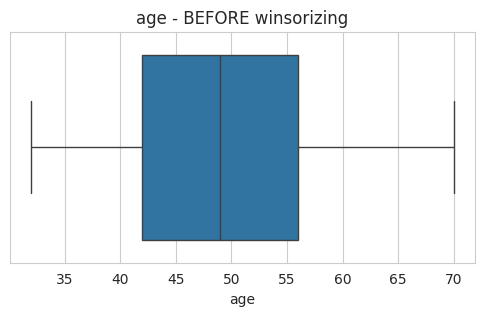

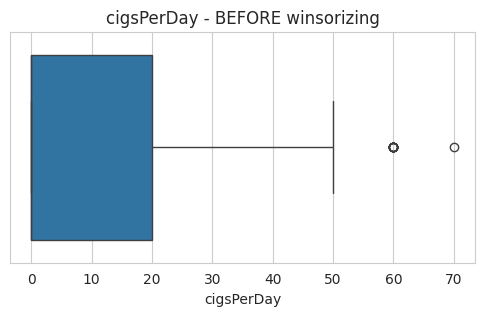

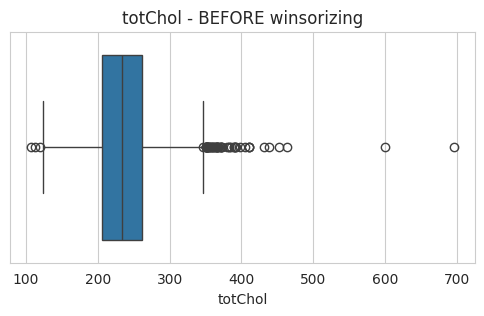

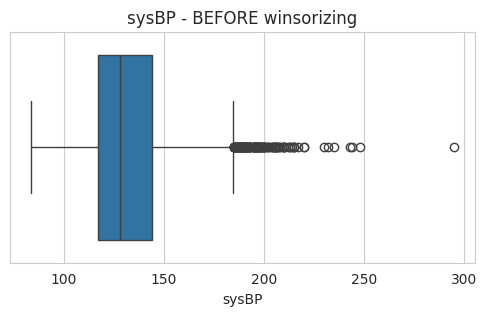

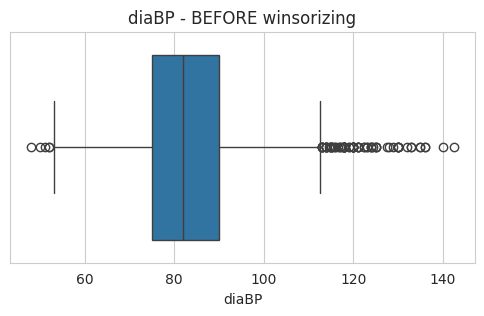

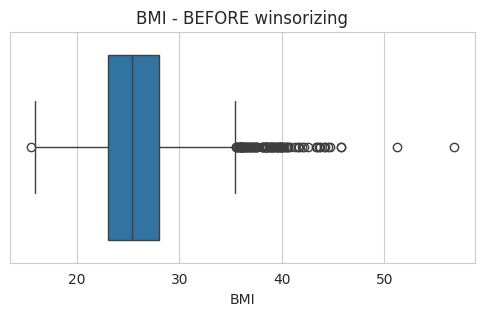

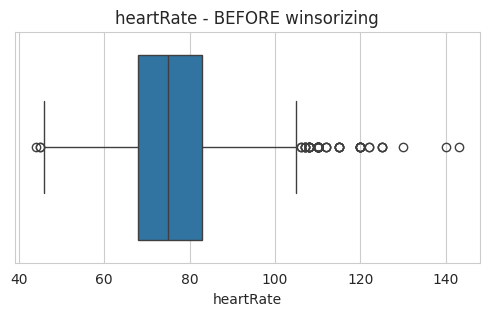

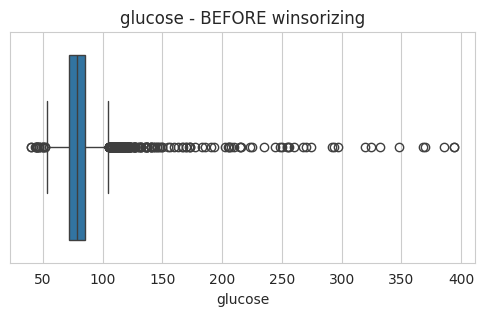


Boxplots AFTER winsorizing (dfOutlierHandled):


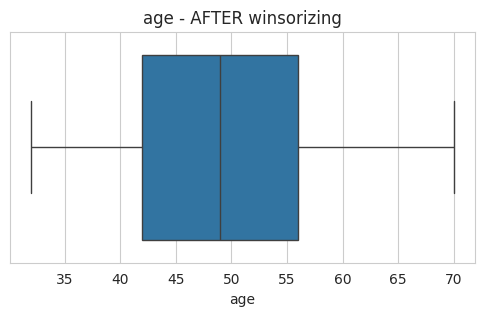

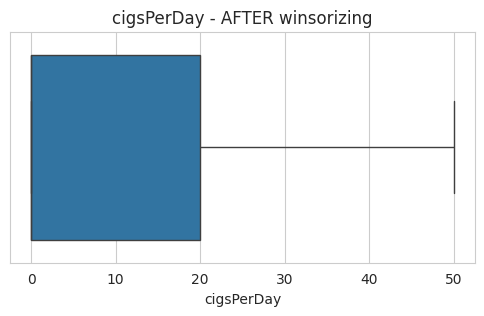

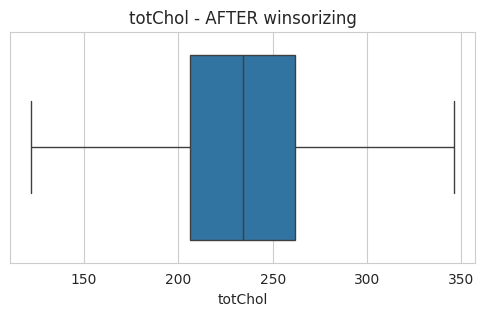

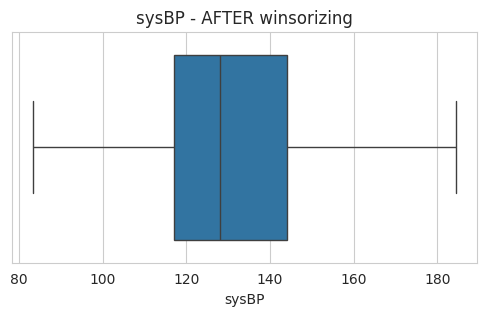

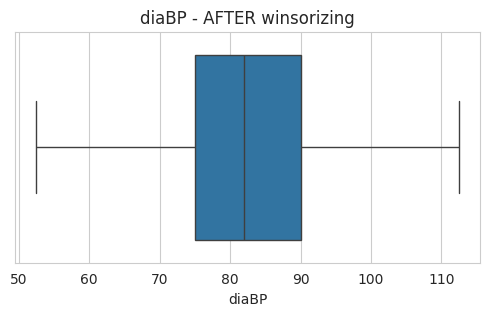

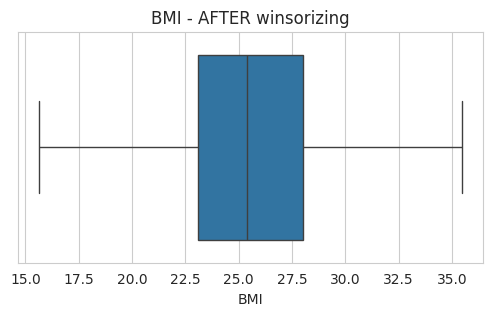

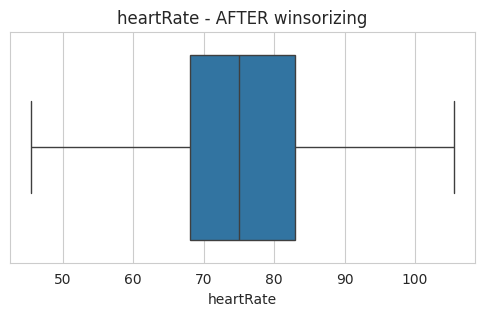

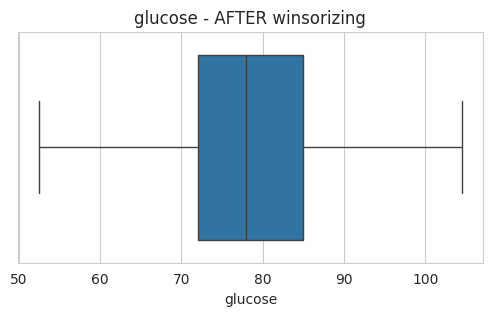


Verification: outlier counts AFTER winsorizing (expected 0):
age: 0 outliers (lower=21.00, upper=77.00)
cigsPerDay: 0 outliers (lower=-30.00, upper=50.00)
totChol: 0 outliers (lower=122.00, upper=346.00)
sysBP: 0 outliers (lower=76.50, upper=184.50)
diaBP: 0 outliers (lower=52.50, upper=112.50)
BMI: 0 outliers (lower=15.65, upper=35.46)
heartRate: 0 outliers (lower=45.50, upper=105.50)
glucose: 0 outliers (lower=52.50, upper=104.50)


In [ ]:
# Step 4: Outlier handling by WINSORIZING (clip to IQR bounds)
# Save "before winsorize" numeric snapshot for plotting
df_before_winsor = dfMissingHandled[numeric_continuous].copy()

# --- Plot BEFORE winsorizing (boxplots)
print("Boxplots BEFORE winsorizing (dfMissingHandled):")
for col in numeric_continuous:
    plt.figure(figsize=(6,3))
    sns.boxplot(x=df_before_winsor[col])
    plt.title(f"{col} - BEFORE winsorizing")
    plt.show()

# --- Apply winsorizing (IQR clip) into a new dataframe dfOutlierHandled
dfOutlierHandled = dfMissingHandled.copy()
for col in numeric_continuous:
    s = dfOutlierHandled[col].astype(float)
    low, up = iqr_bounds(s.dropna())
    dfOutlierHandled[col] = s.clip(lower=low, upper=up)

# --- Plot AFTER winsorizing (boxplots)
print("\nBoxplots AFTER winsorizing (dfOutlierHandled):")
for col in numeric_continuous:
    plt.figure(figsize=(6,3))
    sns.boxplot(x=dfOutlierHandled[col])
    plt.title(f"{col} - AFTER winsorizing")
    plt.show()

# --- Verify no IQR-outliers remain (should be 0 for each numeric column)
print("\nVerification: outlier counts AFTER winsorizing (expected 0):")
for col in numeric_continuous:
    s = dfOutlierHandled[col].astype(float)
    low, up = iqr_bounds(s.dropna())
    mask = (s < low) | (s > up)
    print(f"{col}: {int(mask.sum())} outliers (lower={low:.2f}, upper={up:.2f})")

One Hot Encoding

In [ ]:
# Step 5: One-hot encoding for education
dfEncoded = dfOutlierHandled.copy()

if 'education' in dfEncoded.columns:
    edu_dummies = pd.get_dummies(dfEncoded['education'], prefix='edu', dtype=int)
    dfEncoded = pd.concat([dfEncoded.drop(columns=['education']), edu_dummies], axis=1)
    edu_cols = [c for c in dfEncoded.columns if c.startswith('edu_')]
    print("One-hot columns created:", edu_cols)
else:
    edu_cols = [c for c in dfEncoded.columns if c.startswith('edu_')]
    print("'education' column not found; existing edu cols:", edu_cols)

print("\nCheck head of encoded df:")
display(dfEncoded.head())


One-hot columns created: ['edu_1.0', 'edu_2.0', 'edu_3.0', 'edu_4.0']

Check head of encoded df:


,male,age,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD,edu_1.0,edu_2.0,edu_3.0,edu_4.0
0,1.0,39.0,0.0,0.0,0.0,0.0,0.0,0.0,195.0,106.0,70.0,26.97,80.0,77.0,0,0,0,0,1
1,0.0,46.0,0.0,0.0,0.0,0.0,0.0,0.0,250.0,121.0,81.0,28.73,95.0,76.0,0,0,1,0,0
2,1.0,48.0,1.0,20.0,0.0,0.0,0.0,0.0,245.0,127.5,80.0,25.34,75.0,70.0,0,1,0,0,0
3,0.0,61.0,1.0,30.0,0.0,0.0,1.0,0.0,225.0,150.0,95.0,28.58,65.0,103.0,1,0,0,1,0
4,0.0,46.0,1.0,23.0,0.0,0.0,0.0,0.0,285.0,130.0,84.0,23.10,85.0,85.0,0,0,0,1,0


Feature Engineering

In [ ]:
# Step 6: Feature Engineering — add two new features (PulsePressure & CholAgeRatio)
dfEngineered = dfEncoded.copy()

# Create features
dfEngineered['PulsePressure'] = dfEngineered['sysBP'] - dfEngineered['diaBP']
dfEngineered['CholAgeRatio'] = dfEngineered['totChol'] / (dfEngineered['age'] + 1e-6)

print("Engineered features added: PulsePressure, CholAgeRatio")
print(dfEngineered[['PulsePressure','CholAgeRatio']].describe())
display(dfEngineered.head())


Engineered features added: PulsePressure, CholAgeRatio
       PulsePressure  CholAgeRatio
count    4240.000000   4240.000000
mean       49.172642      4.865042
std        13.699602      1.032104
min        15.000000      1.742857
25%        40.000000      4.155172
50%        47.000000      4.761905
75%        56.000000      5.500000
max       121.500000      8.641025


,male,age,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD,edu_1.0,edu_2.0,edu_3.0,edu_4.0,PulsePressure,CholAgeRatio
0,1.0,39.0,0.0,0.0,0.0,0.0,0.0,0.0,195.0,106.0,70.0,26.97,80.0,77.0,0,0,0,0,1,36.0,5.000000
1,0.0,46.0,0.0,0.0,0.0,0.0,0.0,0.0,250.0,121.0,81.0,28.73,95.0,76.0,0,0,1,0,0,40.0,5.434782
2,1.0,48.0,1.0,20.0,0.0,0.0,0.0,0.0,245.0,127.5,80.0,25.34,75.0,70.0,0,1,0,0,0,47.5,5.104167
3,0.0,61.0,1.0,30.0,0.0,0.0,1.0,0.0,225.0,150.0,95.0,28.58,65.0,103.0,1,0,0,1,0,55.0,3.688525
4,0.0,46.0,1.0,23.0,0.0,0.0,0.0,0.0,285.0,130.0,84.0,23.10,85.0,85.0,0,0,0,1,0,46.0,6.195652


Balancing using SMOTE

✅ SMOTE applied successfully
Before SMOTE shape: (4240, 20)
After SMOTE shape: (7192, 20)

Target distribution after SMOTE:
TenYearCHD
0    3596
1    3596
Name: count, dtype: int64


/tmp/ipython-input-2905319481.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_engine, ax=axes[0], palette="pastel")
/tmp/ipython-input-2905319481.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_smote, ax=axes[1], palette="muted")


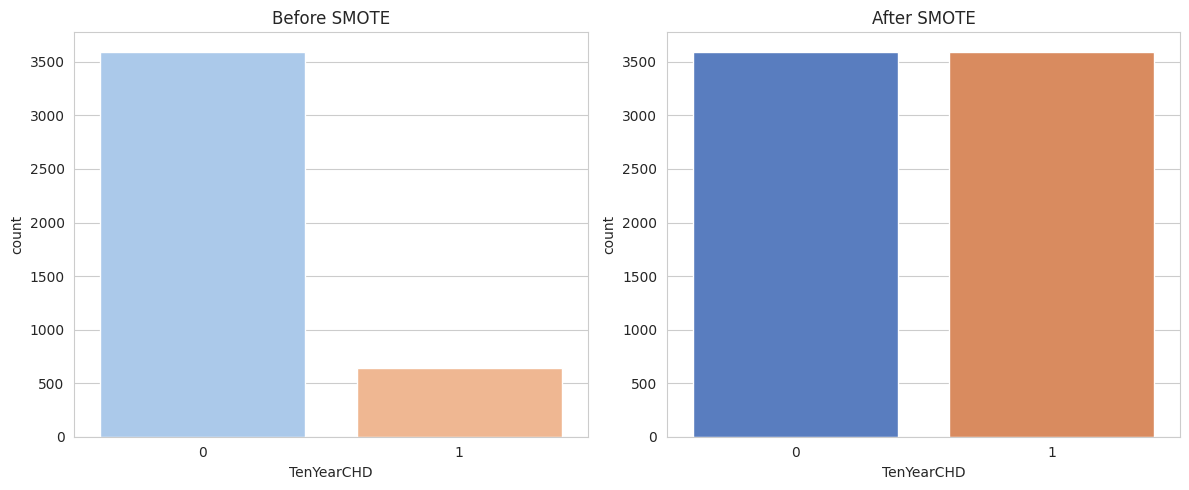

In [ ]:
# Step 7: Apply SMOTE before scaling
from imblearn.over_sampling import SMOTE

# Separate features and target from dfEngineered
X_engine = dfEngineered.drop(columns=['TenYearCHD'])
y_engine = dfEngineered['TenYearCHD']

# Apply SMOTE
smote = SMOTE(random_state=42)
X_smote, y_smote = smote.fit_resample(X_engine, y_engine)

# Convert to DataFrame for consistency
dfSmote = pd.concat([
    pd.DataFrame(X_smote, columns=X_engine.columns),
    pd.Series(y_smote, name='TenYearCHD')
], axis=1)

# Display info
print("✅ SMOTE applied successfully")
print("Before SMOTE shape:", X_engine.shape)
print("After SMOTE shape:", X_smote.shape)
print("\nTarget distribution after SMOTE:")
print(y_smote.value_counts())

# Visualize class balance before vs after
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.countplot(x=y_engine, ax=axes[0], palette="pastel")
axes[0].set_title("Before SMOTE")
sns.countplot(x=y_smote, ax=axes[1], palette="muted")
axes[1].set_title("After SMOTE")
plt.tight_layout()
plt.show()

In [ ]:
Min Max Scaling

In [ ]:
# Step 8: Min-Max scaling on SMOTE dataset
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X_scaled_arr = scaler.fit_transform(X_smote)
X_scaled = pd.DataFrame(X_scaled_arr, columns=X_smote.columns)

# Recombine with target
dfScaled = pd.concat([X_scaled, y_smote.reset_index(drop=True)], axis=1)

print("✅ Scaling done after SMOTE")
print("Scaled dataset shape:", dfScaled.shape)
display(dfScaled.head())

✅ Scaling done after SMOTE
Scaled dataset shape: (7192, 21)


,male,age,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,edu_1.0,edu_2.0,edu_3.0,edu_4.0,PulsePressure,CholAgeRatio,TenYearCHD
0,1.0,0.184211,0.0,0.00,0.0,0.0,0.0,0.0,0.325893,0.222772,0.291667,0.571393,0.575000,0.471154,0.0,0.0,0.0,1.0,0.197183,0.472175,0
1,0.0,0.368421,0.0,0.00,0.0,0.0,0.0,0.0,0.571429,0.371287,0.475000,0.660192,0.825000,0.451923,0.0,1.0,0.0,0.0,0.234742,0.535204,0
2,1.0,0.421053,1.0,0.40,0.0,0.0,0.0,0.0,0.549107,0.435644,0.458333,0.489152,0.491667,0.336538,1.0,0.0,0.0,0.0,0.305164,0.487276,0
3,0.0,0.763158,1.0,0.60,0.0,0.0,1.0,0.0,0.459821,0.658416,0.708333,0.652624,0.325000,0.971154,0.0,0.0,1.0,0.0,0.375587,0.282056,1
4,0.0,0.368421,1.0,0.46,0.0,0.0,0.0,0.0,0.727679,0.460396,0.525000,0.376135,0.658333,0.625000,0.0,0.0,1.0,0.0,0.291080,0.645504,0


Feature Selection

In [ ]:
# Step 9: Feature Selection — Filter / Wrapper / Embedded
X_fs = dfScaled.drop(columns=['TenYearCHD'])
y_fs = dfScaled['TenYearCHD']

print("Feature Selection input shape:", X_fs.shape)

# --- Filter Methods ---
vt = VarianceThreshold(threshold=0.0)
vt.fit(X_fs)
vt_keep_cols = X_fs.columns[vt.get_support()]
print("\nVarianceThreshold kept:", len(vt_keep_cols))

k_chi2 = min(10, X_fs.shape[1])
skb_chi2 = SelectKBest(score_func=chi2, k=k_chi2).fit(X_fs, y_fs)
chi2_keep_cols = X_fs.columns[skb_chi2.get_support()]
print("SelectKBest(chi2) kept:", list(chi2_keep_cols))

k_mi = min(10, X_fs.shape[1])
skb_mi = SelectKBest(score_func=mutual_info_classif, k=k_mi).fit(X_fs, y_fs)
mi_keep_cols = X_fs.columns[skb_mi.get_support()]
print("SelectKBest(MI) kept:", list(mi_keep_cols))

# --- Wrapper Method ---
rfe_est = LogisticRegression(max_iter=2000, solver="liblinear")
rfe = RFE(estimator=rfe_est, n_features_to_select=min(10, X_fs.shape[1]), step=1)
rfe.fit(X_fs, y_fs)
rfe_keep_cols = X_fs.columns[rfe.support_]
print("\nWrapper (RFE+LogReg) kept:", list(rfe_keep_cols))

# --- Embedded Methods ---
l1 = LogisticRegression(penalty="l1", solver="liblinear", max_iter=2000).fit(X_fs, y_fs)
coef = pd.Series(l1.coef_[0], index=X_fs.columns)
embedded_l1_keep_cols = list(coef[coef != 0].index)
print("Embedded (L1 Logistic) kept:", embedded_l1_keep_cols)

rf = RandomForestClassifier(n_estimators=300, random_state=42).fit(X_fs, y_fs)
imp = pd.Series(rf.feature_importances_, index=X_fs.columns).sort_values(ascending=False)
embedded_rf_keep_cols = list(imp.head(min(10, len(imp))).index)
print("Embedded (RandomForest top) kept:", embedded_rf_keep_cols)

# Summary
candidate_sets = {
    "Filter: chi2": set(chi2_keep_cols),
    "Filter: MI": set(mi_keep_cols),
    "Wrapper: RFE": set(rfe_keep_cols),
    "Embedded: L1": set(embedded_l1_keep_cols),
    "Embedded: RF": set(embedded_rf_keep_cols),
}
print("\nSUMMARY — Feature sets to consider:")
for name, s in candidate_sets.items():
    print(f"{name}: {sorted(list(s))}")

Feature Selection input shape: (7192, 20)

VarianceThreshold kept: 20
SelectKBest(chi2) kept: ['male', 'age', 'BPMeds', 'prevalentHyp', 'diabetes', 'sysBP', 'edu_1.0', 'edu_2.0', 'edu_3.0', 'edu_4.0']
SelectKBest(MI) kept: ['male', 'age', 'cigsPerDay', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose', 'PulsePressure']

Wrapper (RFE+LogReg) kept: ['age', 'cigsPerDay', 'BPMeds', 'prevalentStroke', 'diabetes', 'sysBP', 'edu_1.0', 'edu_2.0', 'edu_3.0', 'edu_4.0']
Embedded (L1 Logistic) kept: ['male', 'age', 'currentSmoker', 'cigsPerDay', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes', 'totChol', 'sysBP', 'heartRate', 'glucose', 'edu_1.0', 'edu_2.0', 'edu_3.0', 'edu_4.0', 'PulsePressure']
Embedded (RandomForest top) kept: ['male', 'age', 'PulsePressure', 'sysBP', 'totChol', 'CholAgeRatio', 'prevalentHyp', 'heartRate', 'glucose', 'diaBP']

SUMMARY — Feature sets to consider:
Filter: chi2: ['BPMeds', 'age', 'diabetes', 'edu_1.0', 'edu_2.0', 'edu_3.0', 'edu_4.0', 'male', 'pr

Feature Extraction

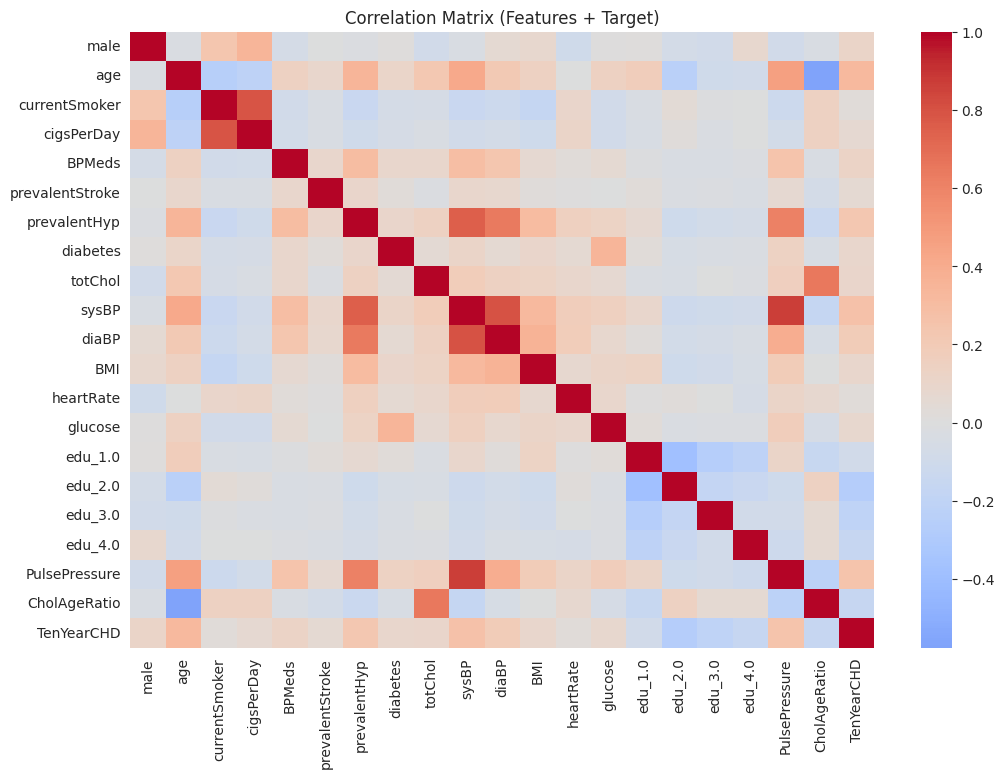

In [ ]:
# Step 10: Feature Extraction (PCA)
from sklearn.decomposition import PCA

# Correlation Matrix before PCA
df_corr = dfScaled.copy()
corr_with_target = df_corr.corr()
plt.figure(figsize=(12, 8))
sns.heatmap(corr_with_target, annot=False, cmap='coolwarm', center=0)
plt.title("Correlation Matrix (Features + Target)")
plt.show()

Applying PCA

In [ ]:
# PCA retaining 95% variance
X_pca = PCA(n_components=0.95, svd_solver="full", random_state=42)
X_pca_arr = X_pca.fit_transform(dfScaled.drop(columns=['TenYearCHD']))
X_pca_df = pd.DataFrame(
    X_pca_arr,
    columns=[f"PC{i+1}" for i in range(X_pca.n_components_)],
    index=dfScaled.index
)

print("✅ PCA completed")
print("Original features:", dfScaled.shape[1]-1)
print("Components kept:", X_pca.n_components_)
print("Variance retained:", round(X_pca.explained_variance_ratio_.sum(), 4))
display(X_pca_df.head())

✅ PCA completed
Original features: 20
Components kept: 13
Variance retained: 0.9508


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13
0,0.334629,-0.296015,-0.182715,0.996244,-0.229305,0.696420,-0.278859,0.181248,-0.403036,0.056036,0.101667,0.037972,0.117098
1,0.105291,-1.068979,-0.092164,-0.044116,0.542842,-0.052368,-0.029165,0.211690,0.051565,0.225365,0.210650,0.034711,0.103972
2,0.502721,0.852519,-0.437862,0.068456,0.135689,-0.076400,-0.120689,0.066346,0.119031,-0.017423,0.035611,0.072997,0.004094
3,-0.117125,0.019687,0.661332,-0.655820,-0.859609,-0.467950,0.282749,-0.167632,-0.321543,-0.242203,0.122981,-0.151624,-0.297350
4,0.590308,-0.309922,-0.047702,-0.549857,-0.860316,-0.440267,0.113900,0.284336,-0.001758,-0.077532,0.167315,0.072582,0.040679


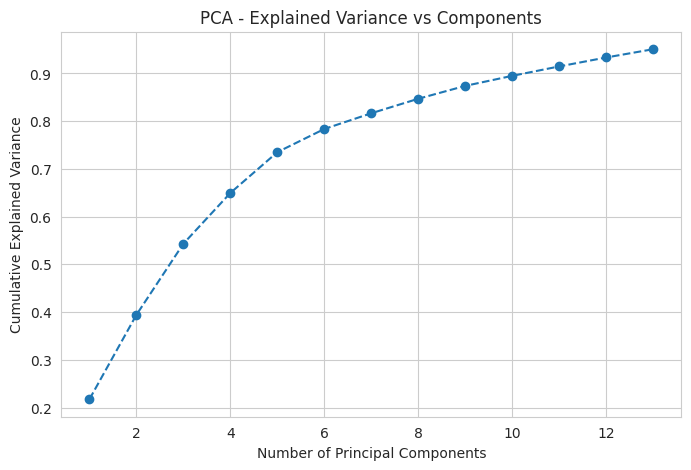

In [ ]:
# Plot explained variance
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(X_pca.explained_variance_ratio_)+1),
         X_pca.explained_variance_ratio_.cumsum(), marker="o", linestyle="--")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Explained Variance vs Components")
plt.grid(True)
plt.show()

In [ ]:
# Combine PCA components with target variable
pca_dataset = pd.concat(
    [X_pca_df, dfScaled['TenYearCHD'].reset_index(drop=True)],
    axis=1
)

# Display shape and head
print("✅ Final PCA dataset shape:", pca_dataset.shape)
display(pca_dataset.head())

✅ Final PCA dataset shape: (7192, 14)


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,TenYearCHD
0,0.334629,-0.296015,-0.182715,0.996244,-0.229305,0.696420,-0.278859,0.181248,-0.403036,0.056036,0.101667,0.037972,0.117098,0
1,0.105291,-1.068979,-0.092164,-0.044116,0.542842,-0.052368,-0.029165,0.211690,0.051565,0.225365,0.210650,0.034711,0.103972,0
2,0.502721,0.852519,-0.437862,0.068456,0.135689,-0.076400,-0.120689,0.066346,0.119031,-0.017423,0.035611,0.072997,0.004094,0
3,-0.117125,0.019687,0.661332,-0.655820,-0.859609,-0.467950,0.282749,-0.167632,-0.321543,-0.242203,0.122981,-0.151624,-0.297350,1
4,0.590308,-0.309922,-0.047702,-0.549857,-0.860316,-0.440267,0.113900,0.284336,-0.001758,-0.077532,0.167315,0.072582,0.040679,0


# EDA

=== EDA for BMI ===


/tmp/ipython-input-1192145228.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="TenYearCHD", y="BMI", data=dfOutlierHandled, ax=axes[2], palette="Set2")


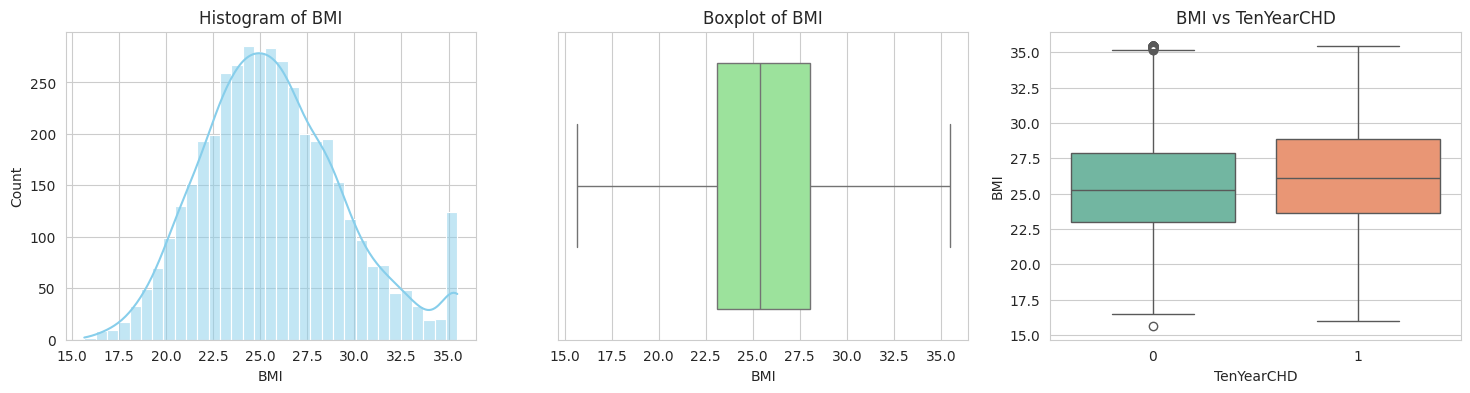

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

print("=== EDA for BMI ===")
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

sns.histplot(dfOutlierHandled["BMI"], kde=True, ax=axes[0], color="skyblue")
axes[0].set_title("Histogram of BMI")

sns.boxplot(x=dfOutlierHandled["BMI"], ax=axes[1], color="lightgreen")
axes[1].set_title("Boxplot of BMI")

sns.boxplot(x="TenYearCHD", y="BMI", data=dfOutlierHandled, ax=axes[2], palette="Set2")
axes[2].set_title("BMI vs TenYearCHD")

plt.show()

=== EDA for Gender (0- Female, 1 - Male) ===


/tmp/ipython-input-2155110120.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=dfOutlierHandled["male"], ax=ax[0], palette="pastel")


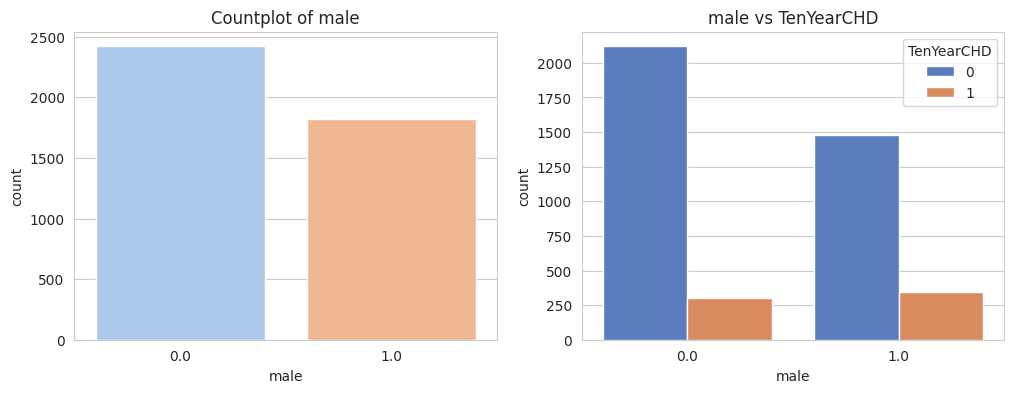

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

print("=== EDA for Gender (0- Female, 1 - Male) ===")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(x=dfOutlierHandled["male"], ax=ax[0], palette="pastel")
ax[0].set_title("Countplot of male")

sns.countplot(x="male", hue="TenYearCHD", data=dfOutlierHandled, ax=ax[1], palette="muted")
ax[1].set_title("male vs TenYearCHD")

plt.show()


=== EDA for totChol ===


/tmp/ipython-input-3073122075.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="TenYearCHD", y="totChol", data=dfOutlierHandled, ax=axes[2], palette="Set2")


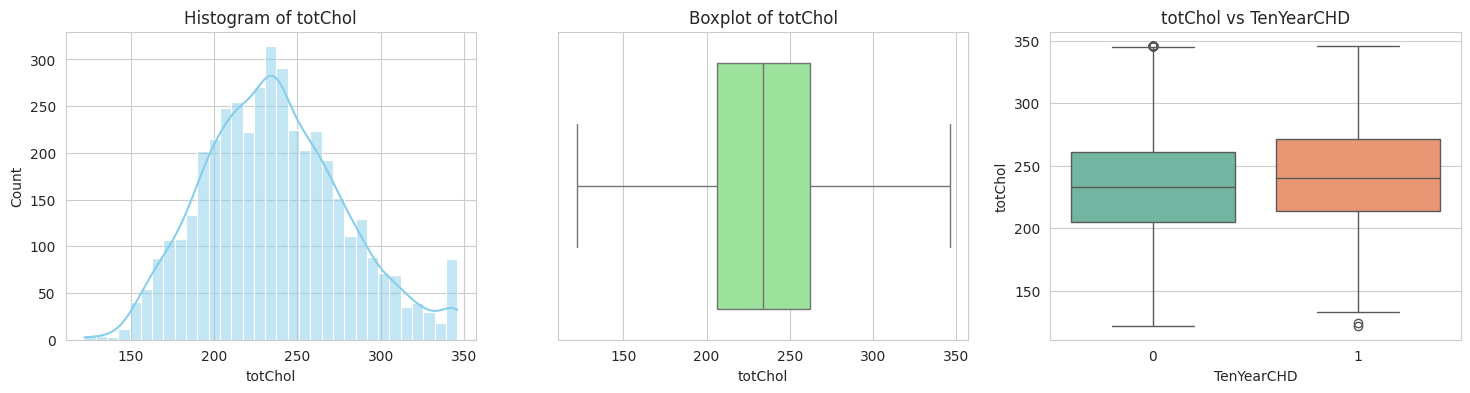

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

print("=== EDA for totChol ===")
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

sns.histplot(dfOutlierHandled["totChol"], kde=True, ax=axes[0], color="skyblue")
axes[0].set_title("Histogram of totChol")

sns.boxplot(x=dfOutlierHandled["totChol"], ax=axes[1], color="lightgreen")
axes[1].set_title("Boxplot of totChol")

sns.boxplot(x="TenYearCHD", y="totChol", data=dfOutlierHandled, ax=axes[2], palette="Set2")
axes[2].set_title("totChol vs TenYearCHD")

plt.show()

=== EDA for age ===


/tmp/ipython-input-3000551755.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="TenYearCHD", y="age", data=dfOutlierHandled, ax=axes[2], palette="Set2")


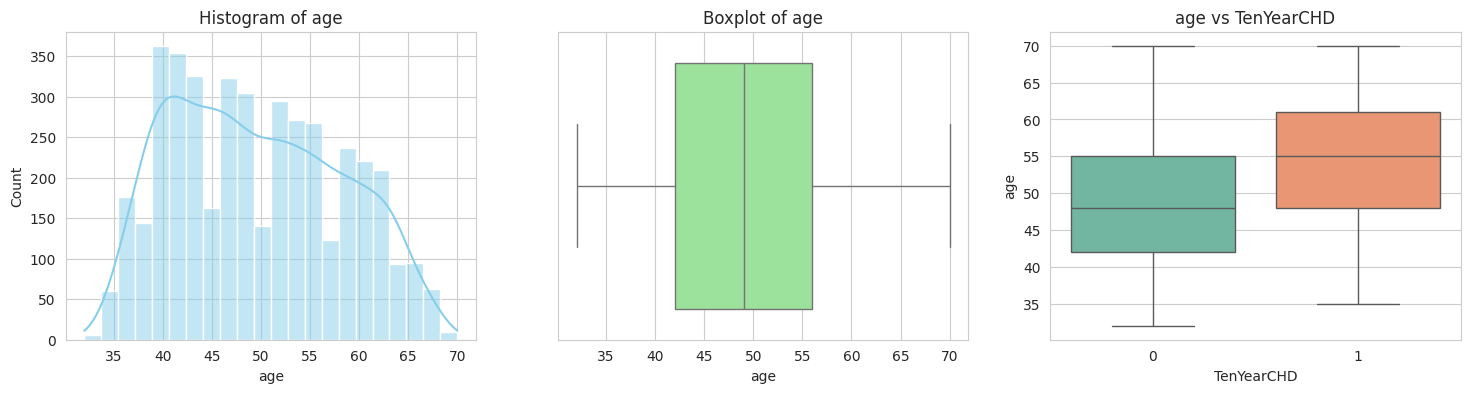

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

print("=== EDA for age ===")
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

sns.histplot(dfOutlierHandled["age"], kde=True, ax=axes[0], color="skyblue")
axes[0].set_title("Histogram of age")

sns.boxplot(x=dfOutlierHandled["age"], ax=axes[1], color="lightgreen")
axes[1].set_title("Boxplot of age")

sns.boxplot(x="TenYearCHD", y="age", data=dfOutlierHandled, ax=axes[2], palette="Set2")
axes[2].set_title("age vs TenYearCHD")

plt.show()


# Train Test Splitting

In [ ]:
# Step: Single Train/Test Split (applies to all upcoming models)
# Dataset: Balanced (SMOTE applied) + Scaled (MinMax scaling done)
print("Using dfScaled for model building (already SMOTE balanced + scaled)")

X_final = dfScaled.drop(columns=['TenYearCHD'])
y_final = dfScaled['TenYearCHD']

from sklearn.model_selection import train_test_split

# One split for all models
X_train, X_test, y_train, y_test = train_test_split(
    X_final, y_final, test_size=0.2, random_state=42, stratify=y_final
)

print("Train shape:", X_train.shape, "Test shape:", X_test.shape)


Using dfScaled for model building (already SMOTE balanced + scaled)
Train shape: (5753, 20) Test shape: (1439, 20)


# Random Forest Model Training





Model 1 : Using all scaled features

In [ ]:
# === MODEL 1: RANDOM FOREST (All Scaled Features) ===
print("\n🔹 MODEL 1 — Using all scaled features")

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
import seaborn as sns
import matplotlib.pyplot as plt



🔹 MODEL 1 — Using all scaled features


In [ ]:
# --------------------------
rf1 = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf1.fit(X_train, y_train)

from sklearn.model_selection import cross_val_score, StratifiedKFold


# Define 5-fold cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Evaluate with cross-validation
cv_scores = cross_val_score(rf1, X_train, y_train, cv=cv, scoring='accuracy', n_jobs=-1)

print("\n=== Cross-Validation Results (Baseline RF) ===")
print("Fold Accuracies:", np.round(cv_scores, 4))
print("Mean CV Accuracy:", np.mean(cv_scores).round(4))
print("Std Dev:", np.std(cv_scores).round(4))


# Predictions
y_pred1 = rf1.predict(X_test)


=== Cross-Validation Results (Baseline RF) ===
Fold Accuracies: [0.8983 0.9235 0.9018 0.907  0.9139]
Mean CV Accuracy: 0.9089
Std Dev: 0.009


In [ ]:
# Metrics
acc1 = accuracy_score(y_test, y_pred1)
prec1 = precision_score(y_test, y_pred1)
rec1 = recall_score(y_test, y_pred1)
f1_1 = f1_score(y_test, y_pred1)

In [ ]:

print(f"\nBaseline Accuracy: {acc1:.4f}, Precision: {prec1:.4f}, Recall: {rec1:.4f}, F1: {f1_1:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred1))


Baseline Accuracy: 0.9048, Precision: 0.9477, Recall: 0.8567, F1: 0.8999

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.95      0.91       720
           1       0.95      0.86      0.90       719

    accuracy                           0.90      1439
   macro avg       0.91      0.90      0.90      1439
weighted avg       0.91      0.90      0.90      1439



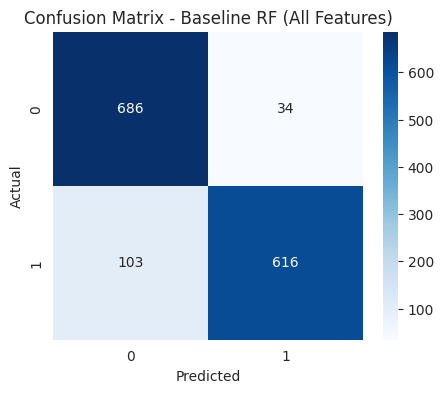

In [ ]:
# Confusion Matrix
plt.figure(figsize=(5,4))
sns.heatmap(confusion_matrix(y_test, y_pred1), annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix - Baseline RF (All Features)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
# 2️⃣ Training Curve
# --------------------------
train_scores, test_scores = [], []
for n in [50, 100, 200, 300, 400]:
    rf_temp = RandomForestClassifier(n_estimators=n, random_state=42, n_jobs=-1)
    rf_temp.fit(X_train, y_train)
    train_scores.append(rf_temp.score(X_train, y_train))
    test_scores.append(rf_temp.score(X_test, y_test))


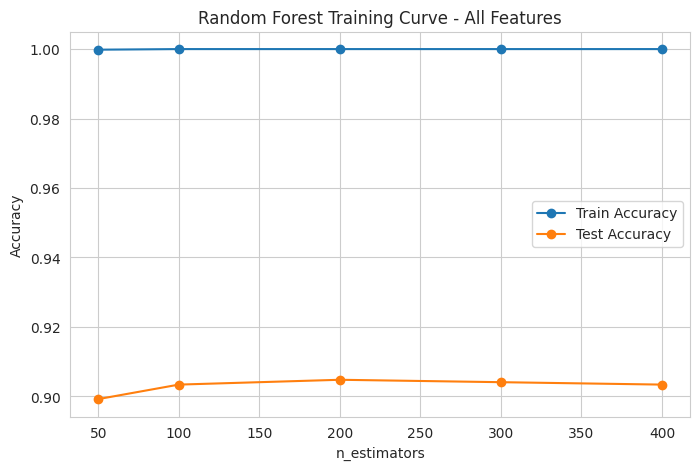

In [ ]:
plt.figure(figsize=(8,5))
plt.plot([50,100,200,300,400], train_scores, label='Train Accuracy', marker='o')
plt.plot([50,100,200,300,400], test_scores, label='Test Accuracy', marker='o')
plt.xlabel("n_estimators")
plt.ylabel("Accuracy")
plt.title("Random Forest Training Curve - All Features")
plt.legend()
plt.grid(True)
plt.show()

Hyperparameter Tuning

In [ ]:
# Random Forest (Improved Manual Hyperparameter Tuning)


from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

In [ ]:

# Final Manual Hyperparameter Tuning

rf_tuned2 = RandomForestClassifier(
    n_estimators=400,          # more trees → better generalization
    max_depth=None,            # allow deeper trees
    min_samples_split=2,
    min_samples_leaf=1,
    max_features='sqrt',       # ✅ FIXED (was 'auto' before)
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

In [ ]:

# Train tuned model
rf_tuned2.fit(X_train, y_train)
y_pred_tuned2 = rf_tuned2.predict(X_test)

cv_scores_tuned2 = cross_val_score(rf_tuned2, X_train, y_train, cv=cv, scoring='accuracy', n_jobs=-1)
print("\n=== Cross-Validation Results (Tuned RF #2) ===")
print("Fold Accuracies:", np.round(cv_scores_tuned2, 4))
print("Mean CV Accuracy:", np.mean(cv_scores_tuned2).round(4))
print("Std Dev:", np.std(cv_scores_tuned2).round(4))


=== Cross-Validation Results (Tuned RF #2) ===
Fold Accuracies: [0.8949 0.9262 0.9018 0.907  0.9157]
Mean CV Accuracy: 0.9091
Std Dev: 0.0109


In [ ]:
# Evaluate tuned model
# --------------------------------
acc_tuned2 = accuracy_score(y_test, y_pred_tuned2)
prec_tuned2 = precision_score(y_test, y_pred_tuned2)
rec_tuned2 = recall_score(y_test, y_pred_tuned2)
f1_tuned2 = f1_score(y_test, y_pred_tuned2)

print("=== Improved Tuned Random Forest Performance ===")
print(f"Accuracy: {acc_tuned2:.4f}")
print(f"Precision: {prec_tuned2:.4f}")
print(f"Recall: {rec_tuned2:.4f}")
print(f"F1 Score: {f1_tuned2:.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred_tuned2))

=== Improved Tuned Random Forest Performance ===
Accuracy: 0.9034
Precision: 0.9394
Recall: 0.8623
F1 Score: 0.8992

Classification Report:
               precision    recall  f1-score   support

           0       0.87      0.94      0.91       720
           1       0.94      0.86      0.90       719

    accuracy                           0.90      1439
   macro avg       0.91      0.90      0.90      1439
weighted avg       0.91      0.90      0.90      1439



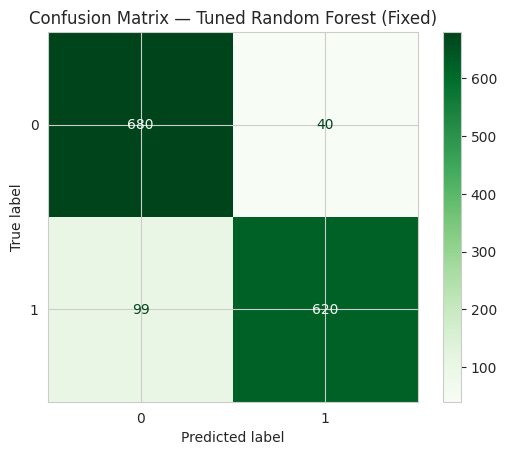

In [ ]:
# Confusion Matrix
cm_tuned2 = confusion_matrix(y_test, y_pred_tuned2)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_tuned2, display_labels=rf_tuned2.classes_)
disp.plot(cmap='Greens', values_format='d')
plt.title("Confusion Matrix — Tuned Random Forest (Fixed)")
plt.show()


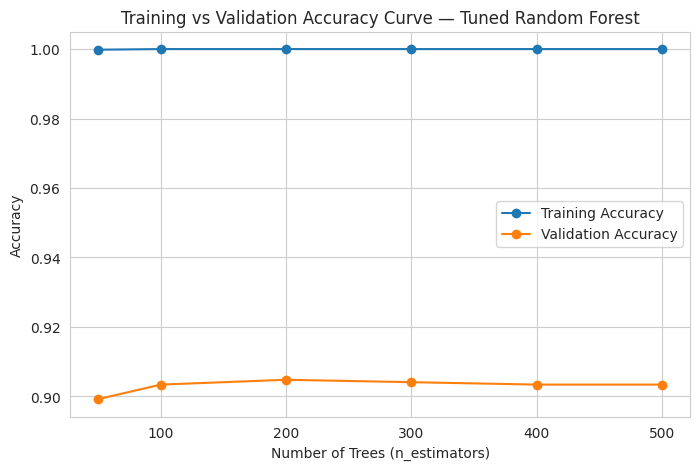

In [ ]:
# Training vs Validation Accuracy Curve
# --------------------------------
n_trees = [50, 100, 200, 300, 400, 500]
train_scores, test_scores = [], []

for n in n_trees:
    model = RandomForestClassifier(n_estimators=n, random_state=42, n_jobs=-1, max_features='sqrt')
    model.fit(X_train, y_train)
    train_scores.append(model.score(X_train, y_train))
    test_scores.append(model.score(X_test, y_test))

plt.figure(figsize=(8,5))
plt.plot(n_trees, train_scores, label='Training Accuracy', marker='o')
plt.plot(n_trees, test_scores, label='Validation Accuracy', marker='o')
plt.title("Training vs Validation Accuracy Curve — Tuned Random Forest")
plt.xlabel("Number of Trees (n_estimators)")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

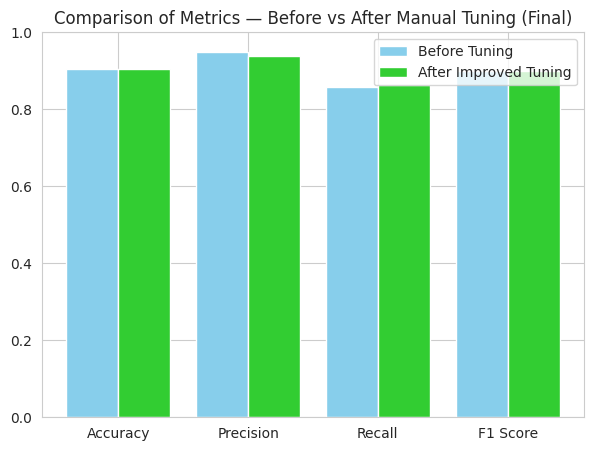

In [ ]:
# Compare Before vs After Manual Tuning
# --------------------------------
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

# Baseline (before tuning)
before = [0.9048, 0.9477, 0.8567, 0.8999]

# After improved tuning
after2 = [acc_tuned2, prec_tuned2, rec_tuned2, f1_tuned2]

x = np.arange(len(metrics))
plt.figure(figsize=(7,5))
plt.bar(x-0.2, before, width=0.4, label="Before Tuning", color="skyblue")
plt.bar(x+0.2, after2, width=0.4, label="After Improved Tuning", color="limegreen")
plt.xticks(x, metrics)
plt.ylim(0,1)
plt.title("Comparison of Metrics — Before vs After Manual Tuning (Final)")
plt.legend()
plt.show()

/tmp/ipython-input-3181900461.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


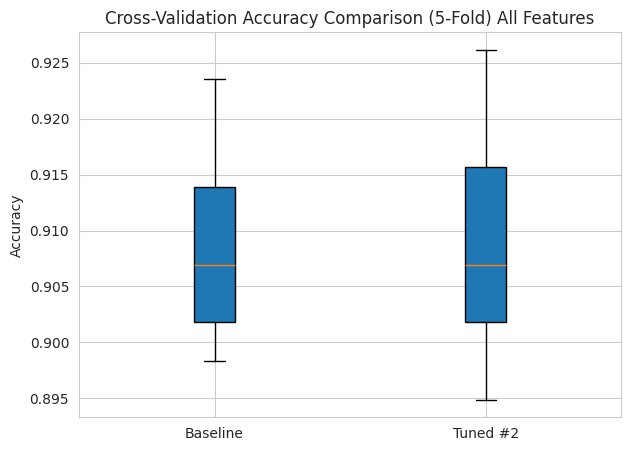

In [ ]:
plt.figure(figsize=(7,5))
plt.boxplot(
    [cv_scores,  cv_scores_tuned2],
    labels=['Baseline', 'Tuned #2'],
    patch_artist=True
)
plt.title("Cross-Validation Accuracy Comparison (5-Fold) All Features")
plt.ylabel("Accuracy")
plt.grid(True)
plt.show()
